In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")
df.head()

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan


In [5]:
df.info()
missing = len(df) - df.count()
missing[missing > 0]    

<class 'pandas.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[us]
 1   dropoff          6433 non-null   datetime64[us]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   str           
 9   payment          6389 non-null   str           
 10  pickup_zone      6407 non-null   str           
 11  dropoff_zone     6388 non-null   str           
 12  pickup_borough   6407 non-null   str           
 13  dropoff_borough  6388 non-null   str           
dtypes: datetime64[us](2), float64(5), int64(1), str(6)


payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

In [3]:
for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

In [5]:
for col in ["payment", "dropoff_zone", "dropoff_borough"]:
    df[col] = df[col].fillna(df[col].mode()[0])

In [6]:
df = df.dropna(subset=["pickup_zone", "pickup_borough"])

In [7]:
len(df) - df.count()

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
trip_count         0
dtype: int64

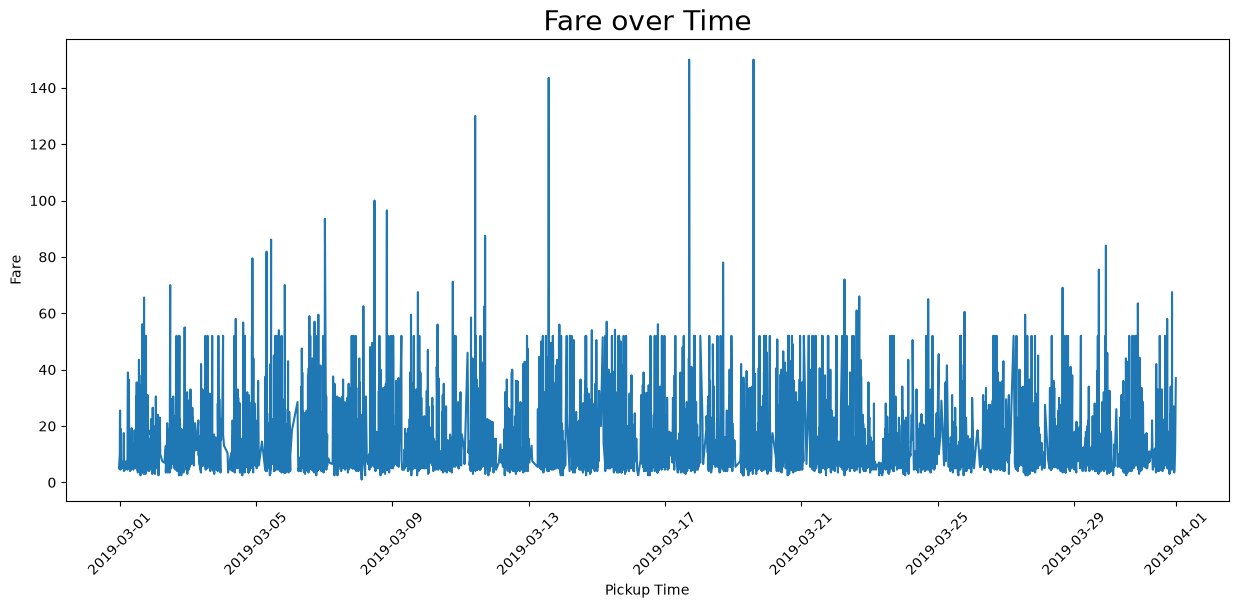

In [8]:
df["pickup"] = pd.to_datetime(df["pickup"])
df.dtypes["pickup"]

df_time = df.sort_values("pickup")

plt.figure(figsize=(15, 6))
plt.plot(df_time["pickup"], df_time["fare"])
plt.title("Fare over Time", fontsize=20)
plt.xlabel("Pickup Time")
plt.ylabel("Fare")
plt.xticks(rotation=45)
plt.show()

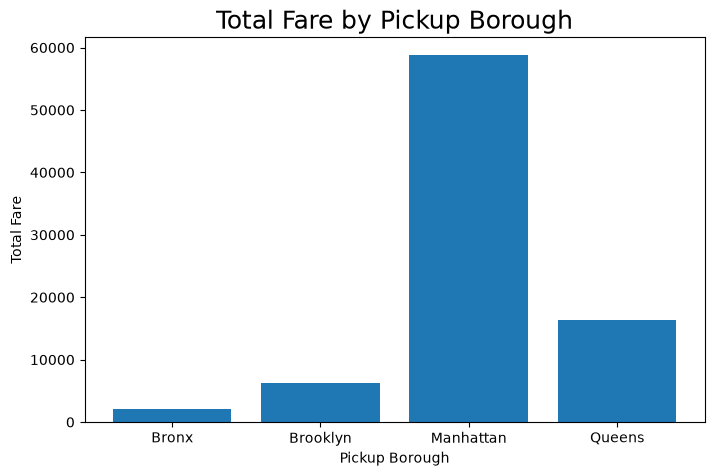

In [9]:
borough_fare = df.groupby("pickup_borough")["fare"].sum()

plt.figure(figsize=(8, 5))
plt.bar(range(0, len(borough_fare)), borough_fare)
plt.xticks(range(0, len(borough_fare)), borough_fare.index)
plt.title("Total Fare by Pickup Borough", fontsize=18)
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.show()

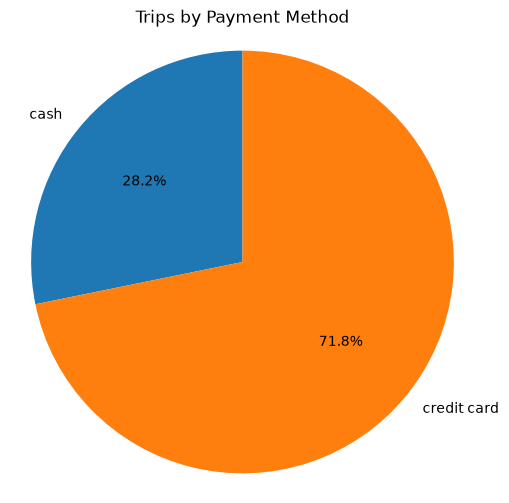

In [10]:
payment_count = df.groupby("payment")["trip_count"].sum()

plt.figure(figsize=(6, 6))
plt.pie(payment_count, labels=payment_count.index, autopct='%1.1f%%', startangle=90)
plt.title("Trips by Payment Method")
plt.axis('equal')
plt.show()

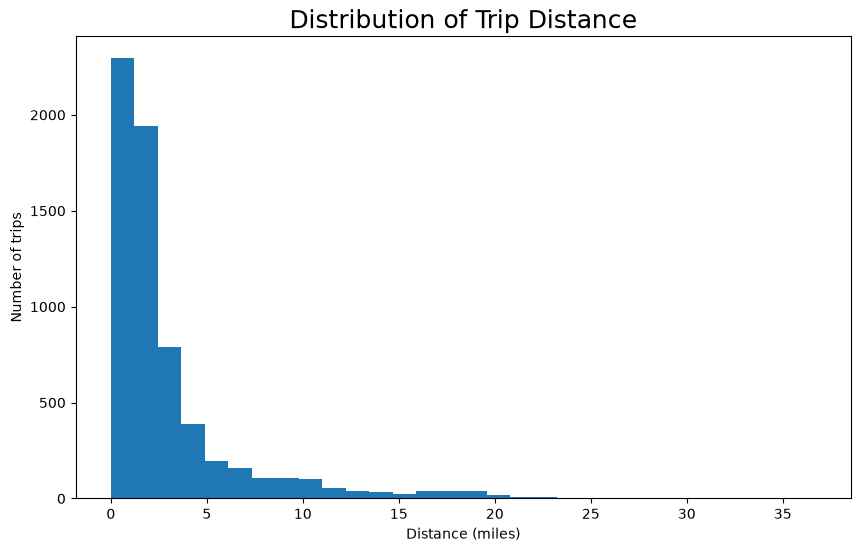

In [11]:
plt.figure(figsize=(10, 6))
plt.hist(df["distance"], 30)
plt.title("Distribution of Trip Distance", fontsize=18)
plt.xlabel("Distance (miles)")
plt.ylabel("Number of trips")
plt.show()

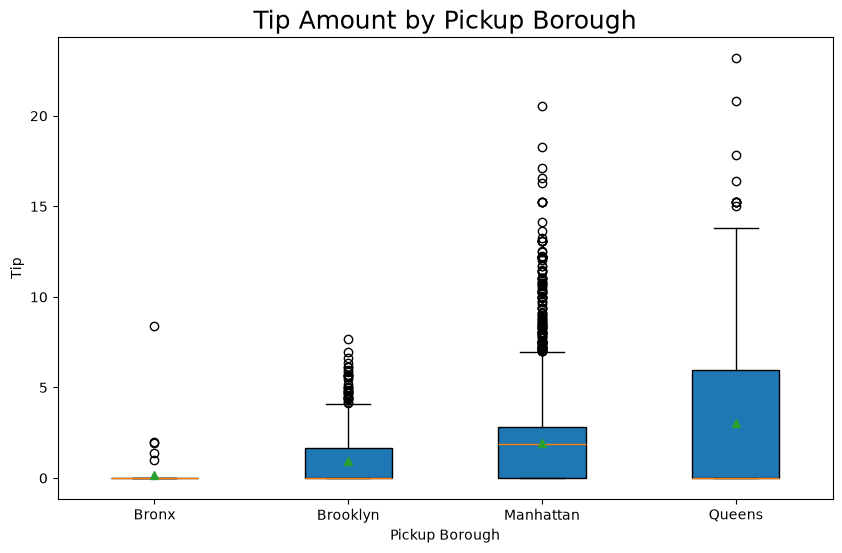

In [12]:
groups = df[["pickup_borough", "tip"]].groupby("pickup_borough")

tip_data = []
borough_names = []
for borough, group in groups:
    tip_data.append(group["tip"])
    borough_names.append(borough)

plt.figure(figsize=(10, 6))
plt.boxplot(tip_data, patch_artist=True, showmeans=True)
plt.xticks(range(1, len(borough_names) + 1), borough_names)
plt.title("Tip Amount by Pickup Borough", fontsize=18)
plt.xlabel("Pickup Borough")
plt.ylabel("Tip")
plt.show()

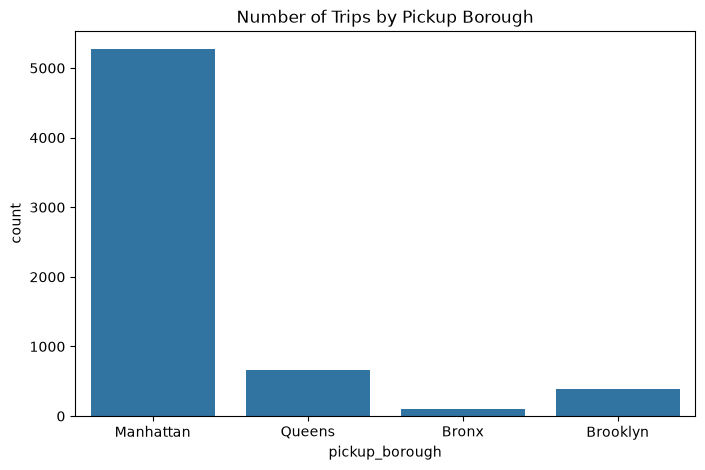

In [13]:
plt.figure(figsize=(8, 5))
sns.countplot(x='pickup_borough', data=df)
plt.title("Number of Trips by Pickup Borough")
plt.show()

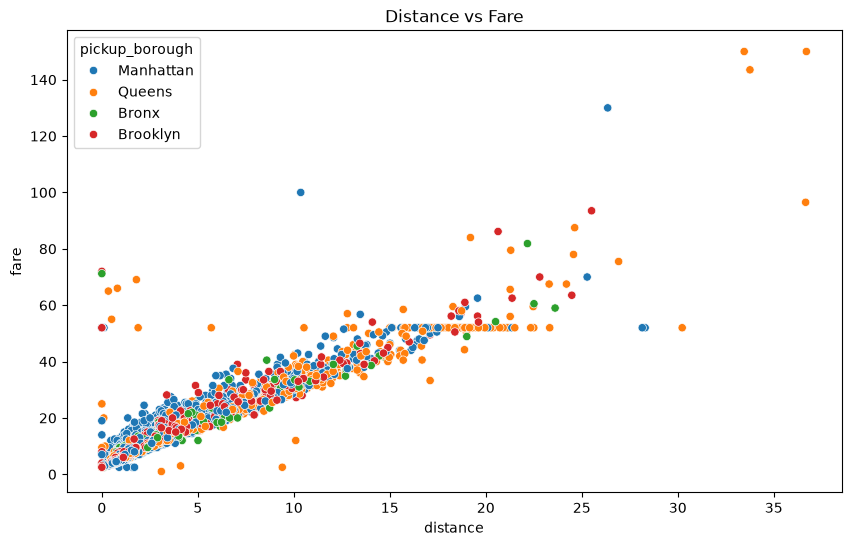

In [14]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='distance', y='fare', hue='pickup_borough', data=df)
plt.title("Distance vs Fare")
plt.show()

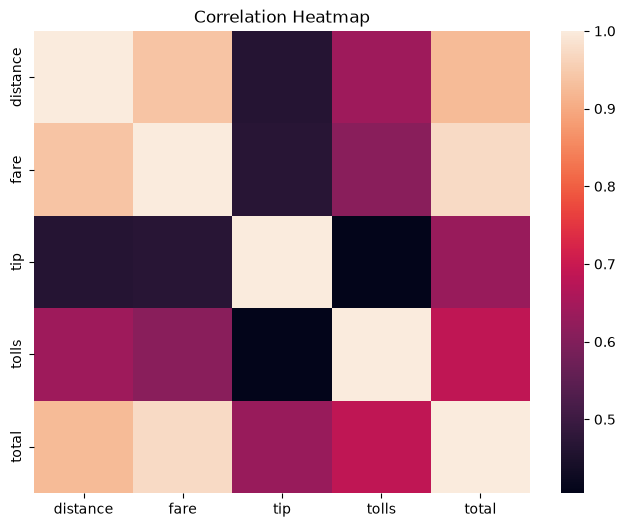

In [15]:
num_df = df[["distance", "fare", "tip", "tolls", "total"]]
num_df.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(num_df.corr())
plt.title("Correlation Heatmap")
plt.show()

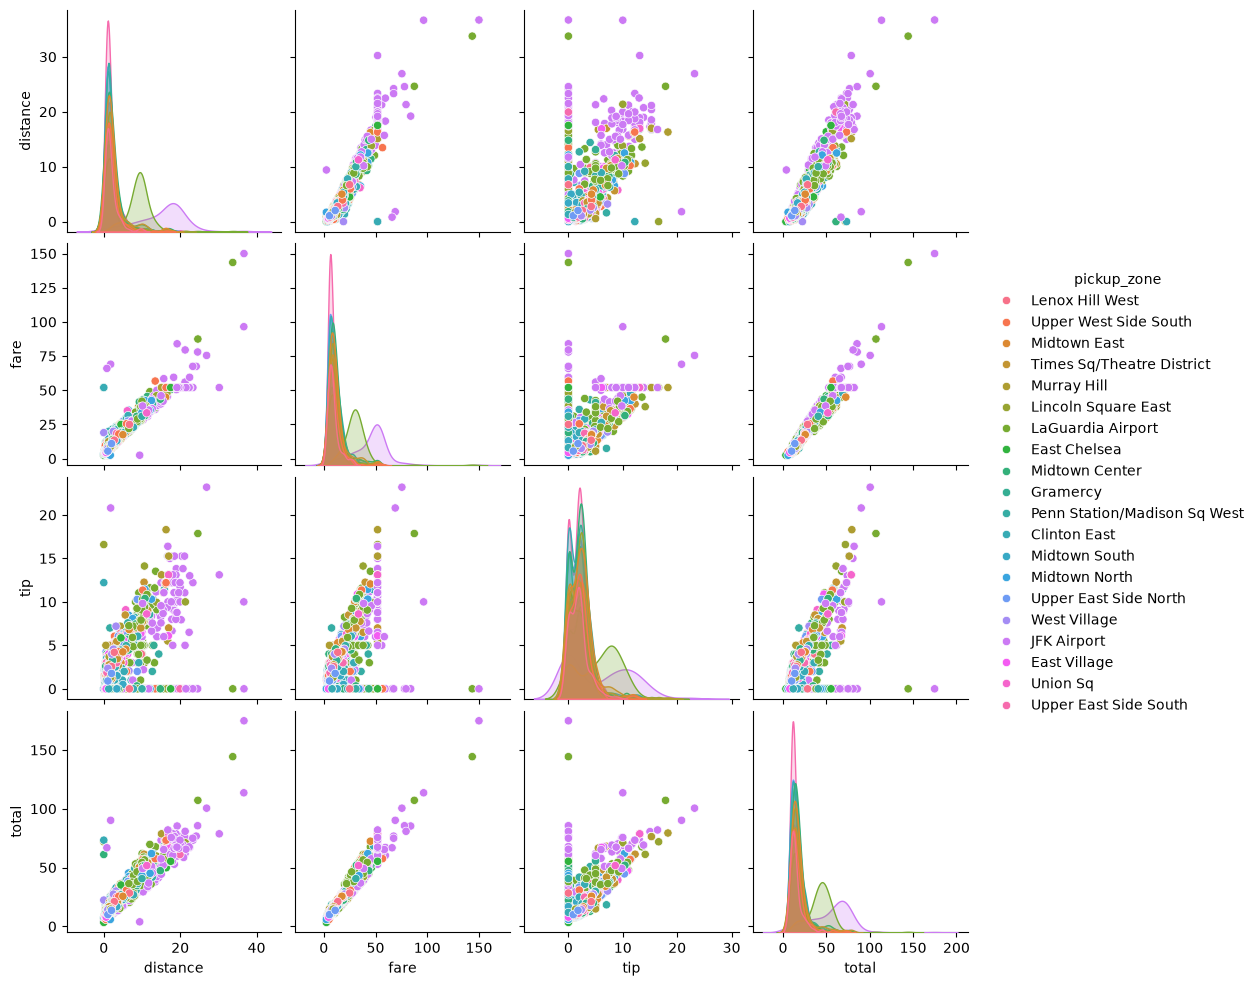

In [21]:
zone_count = df.groupby("pickup_zone")["trip_count"].sum().sort_values(ascending=False)
top_zones = zone_count.head(20).index

df_top = df[df["pickup_zone"].isin(top_zones)]

sns.pairplot(df_top[["distance", "fare", "tip", "total", "pickup_zone"]], hue="pickup_zone")
plt.show()

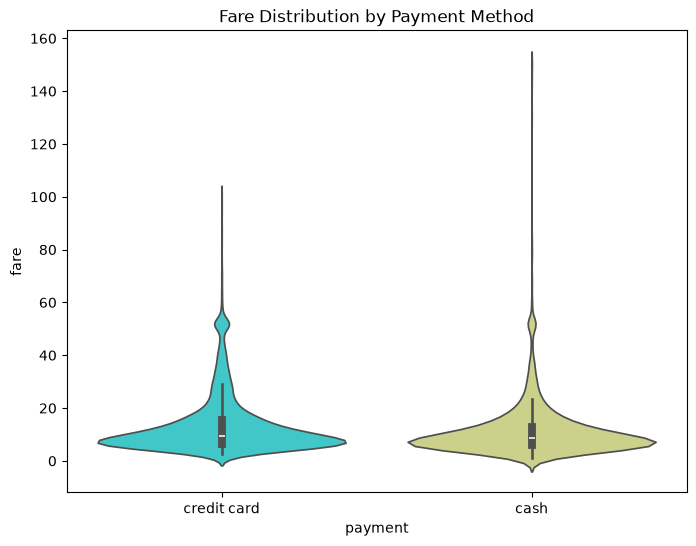

In [17]:
plt.figure(figsize=(8, 6))
sns.violinplot(x="payment", y="fare", hue="payment", data=df, palette='rainbow')
plt.title("Fare Distribution by Payment Method")
plt.show()